# SVMs and Kernels

This notebook aims to introduce linear and kernel (non-linear) SVMs (Support Vector Machines).

In [1]:
# import numpy as np, matplotlib as plt
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
plt.rc('font', **{'size': 12}) # globally sets the font size for plots (in pt)

In [3]:
import pandas as pd

## 1. Loading the Data

We will try to predict the species of a penguin based on its physical characteristics using Support Vector Machines (SVM).

For this, we will use the palmerpenguins dataset, an alternative to the now classic scikit-learn iris dataset. For more information, you can visit the site: https://allisonhorst.github.io/palmerpenguins/index.html

It contains the characteristics of three penguin species surveyed on the Palmer Archipelago, off the northwest coast of the Antarctic Peninsula.

In [4]:
palmerpenguins = pd.read_csv("penguins_data.csv")

In [5]:
palmerpenguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Data Description

In [6]:
print(palmerpenguins.shape)

(344, 8)


In [7]:
import collections
print(collections.Counter(palmerpenguins.species))

Counter({'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68})


**344** pingouins avec **8** attributs:
- *species* : Adelie (152 pinguins), Gentoo (124 pinguins) et Ginstrap (68 pinguins)
- *island* : Biscoe, Dream and Torgersen
- *bill_length_mm* :  bill length in mm
- *bil_depth_mm*:  bill depth in mm
- *flipper_length_mm*:  flipper length in mm
- *body_mass_g*:  weight in g
- *sex*: male et female
- *year*: year of data collection

### Missing data

In [8]:
palmerpenguins.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

You'll notice there are some observations for which information is missing. These are called **missing values**.
Here we decide to ignore these observations.

In [9]:
palmerpenguins = palmerpenguins[palmerpenguins['bill_depth_mm'].notna()]
palmerpenguins = palmerpenguins.reset_index()
palmerpenguins.shape

(342, 9)

So we have only 342 samples left.

Instead of ignoring incomplete observations, a solution that often proves better (from the perspective of the performance of decision models built from the data) is to **estimate** (or **impute**) the missing data and treat the estimated values as measured values.
For this we could have used the SimpleImputer function from sklearn.impute. For more information, you can visit the site: https://scikit-learn.org/stable/modules/impute.html

### Variables

From now on, we will only focus on the numerical variables *bill_depth_mm*,  *bill_length_mm*, *flipper_length_mm* et *body_mass_g*.

In [10]:
penguins_features = palmerpenguins[["bill_length_mm", "bill_depth_mm","body_mass_g", "flipper_length_mm"]]

### Labels

We will try to predict the species. It will be easier to handle the species as integers rather than text.

In [11]:
species_names, species_int = np.unique(palmerpenguins.species, return_inverse=True)
print(species_names)

['Adelie' 'Chinstrap' 'Gentoo']


In [12]:
penguins_labels = pd.DataFrame(palmerpenguins["species"])
penguins_labels["species_int"] = species_int

In [13]:
penguins_labels

,species,species_int
0,Adelie,0
1,Adelie,0
2,Adelie,0
3,Adelie,0
4,Adelie,0
...,...,...
337,Chinstrap,1
338,Chinstrap,1
339,Chinstrap,1
340,Chinstrap,1


## 2. Linear SVM (linearly separable case)

Here we will limit ourselves to two species: Adelie (0) and Gentoo (2) and two variables: *bill_length_mm* and *bill_depth_mm*.

### Restriction of data to the two chosen variables and two labels

In [14]:
labels = penguins_labels[penguins_labels["species_int"].isin([0,2])]
labels = np.array(labels["species_int"])
print("shape de y:", labels.shape)

data = penguins_features[penguins_labels["species_int"].isin([0,2])]
data = np.array(data[["bill_depth_mm", "bill_length_mm"]])
print("shape de X:", data.shape)

shape de y: (274,)
shape de X: (274, 2)


### Data Visualization

/var/folders/7c/np65yykn28x13ygwf_bqkm140000gn/T/ipykernel_8441/2136262251.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  adelie = plt.scatter(data[adelie_indices][:, 0],
/var/folders/7c/np65yykn28x13ygwf_bqkm140000gn/T/ipykernel_8441/2136262251.py:12: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  gentoo = plt.scatter(data[gentoo_indices][:, 0],


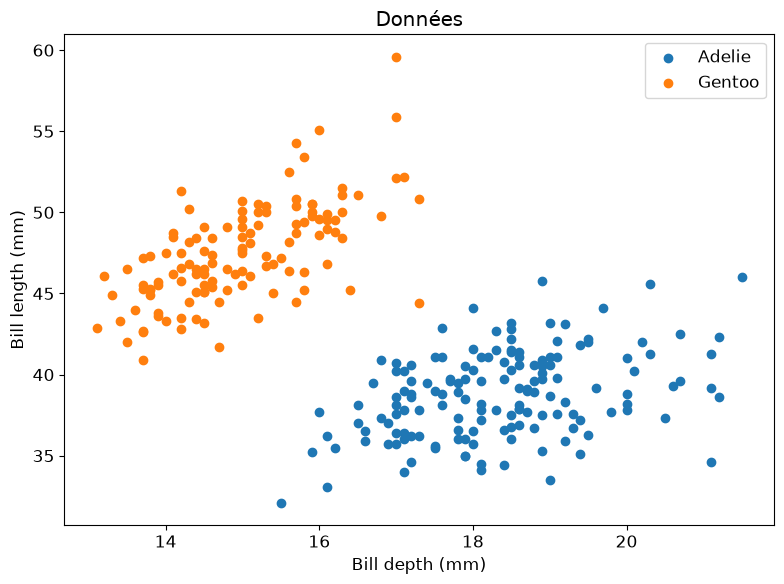

In [15]:
plt.figure(figsize=(8, 6))

# plot the data (pingouins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data[adelie_indices][:, 0],
                    data[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# plot the data (pingouins Gentoo)
gentoo_indices = np.where(labels==2)[0]
gentoo = plt.scatter(data[gentoo_indices][:, 0],
                    data[gentoo_indices][:, 1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)

# Legend
plt.legend()
plt.xlabel("Bill depth (mm)")
plt.ylabel("Bill length (mm)")
plt.title("Données")
plt.tight_layout()

__Question :__ Does the classification problem seem easy or difficult? Can you train a linear model?

### Linear SVM

We will use [SVC](http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC) du module `svm` de scikit-learn to train a linear SVM on this data.

In [16]:
from sklearn import svm

In [17]:
# initialization
model_svc = svm.SVC(kernel='linear', C=10)

# training
model_svc.fit(data, labels)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Model performance is :

In [19]:
print("Score of the linear (C=10): %.2f" % model_svc.score(data, labels))

Score of the linear (C=10): 1.00


__Question :__ What score is this? Use
```
help(model_svc.score)
```

In [20]:
help(model_svc.score)

Help on method score in module sklearn.base:

score(X, y, sample_weight=None) method of sklearn.svm._classes.SVC instance
    Return :ref:`accuracy <accuracy_score>` on provided data and labels.

    In multi-label classification, this is the subset accuracy
    which is a harsh metric since you require for each sample that
    each label set be correctly predicted.

    Parameters
    ----------
    X : array-like of shape (n_samples, n_features)
        Test samples.

    y : array-like of shape (n_samples,) or (n_samples, n_outputs)
        True labels for `X`.

    sample_weight : array-like of shape (n_samples,), default=None
        Sample weights.

    Returns
    -------
    score : float
        Mean accuracy of ``self.predict(X)`` w.r.t. `y`.



__Question :__ What does this performance mean?

We can also display the confusion matrix:

In [21]:
from sklearn import metrics

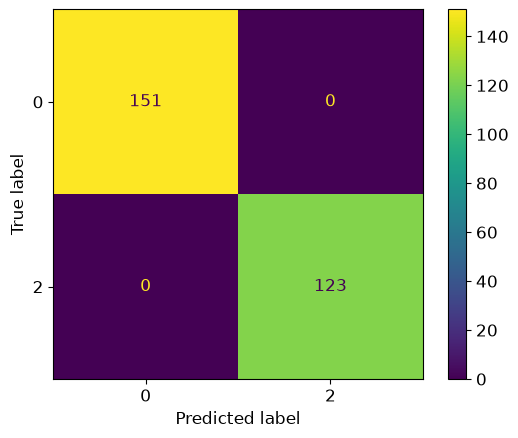

In [22]:
metrics.ConfusionMatrixDisplay.from_predictions(labels, model_svc.predict(data))

Or :

In [23]:
metrics.confusion_matrix(labels, model_svc.predict(data))

array([[151,   0],
       [  0, 123]])

### Separating Hyperplane

We can now visualize the decision boundary:

/var/folders/7c/np65yykn28x13ygwf_bqkm140000gn/T/ipykernel_8441/3984193172.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  adelie = plt.scatter(data[adelie_indices][:, 0],
/var/folders/7c/np65yykn28x13ygwf_bqkm140000gn/T/ipykernel_8441/3984193172.py:12: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  gentoo = plt.scatter(data[gentoo_indices][:, 0],


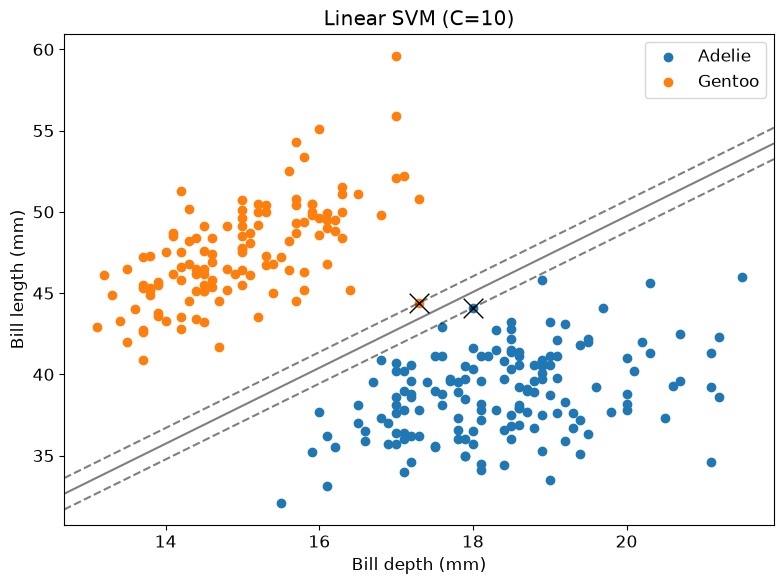

In [24]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data[adelie_indices][:, 0],
                    data[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Gentoo)
gentoo_indices = np.where(labels==2)[0]
gentoo = plt.scatter(data[gentoo_indices][:, 0],
                    data[gentoo_indices][:, 1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)

# Frame limits
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Mark support vectors with a cross
ax.scatter(model_svc.support_vectors_[:, 0],
           model_svc.support_vectors_[:, 1],
           linewidth=1,
           marker='x', s=200,
           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
#
#Predict for grid points
Z = model_svc.decision_function(xy).reshape(XX.shape)

# Plot the decision boundary and margin
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Légende
plt.legend()
plt.xlabel("Bill depth (mm)")
plt.ylabel("Bill length (mm)")
plt.title("Linear SVM (C=10)")
plt.tight_layout()

__Question :__ Which points are support vectors?

### With a smaller C

__Question :__ What can we expect with a lower C value?

Let's check this in practice:

In [ ]:
# initialization
model_svc_01 = svm.SVC(kernel='linear', C=0.1)

# training
model_svc_01.fit(data, labels)

Let's display the performance of the predictor:

In [ ]:
print("Score of the linear SVM (C=0.1): %.2f" % model_svc_01.score(data, labels))

In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(labels, model_svc_01.predict(data))

Or :

In [ ]:
metrics.confusion_matrix(labels, model_svc_01.predict(data))

Let's plot the new decision boundary:

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data[adelie_indices][:, 0],
                    data[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot (pinguins Gentoo)
gentoo_indices = np.where(labels==2)[0]
gentoo = plt.scatter(data[gentoo_indices][:, 0],
                    data[gentoo_indices][:, 1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)


ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

## Previous model
# Mark support vectors with a cross
#ax.scatter(model_svc.support_vectors_[:, 0],
#           model_svc.support_vectors_[:, 1],
#           linewidth=1,
#           marker='x', s=200,
#           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Predict for grid points
Z = model_svc.decision_function(xy).reshape(XX.shape)

## New model
# Mark support vectors with a cross
ax.scatter(model_svc_01.support_vectors_[:, 0],
           model_svc_01.support_vectors_[:, 1],
           linewidth=1,
           marker='+', s=200,
           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Prédire pour les points de la grille
Z = model_svc_01.decision_function(xy).reshape(XX.shape)

# Display the decision boundary and margin
ax.contour(XX, YY, Z, colors='g', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Légende
plt.legend()
plt.xlabel("Bill depth (mm)")
plt.ylabel("Bill length (mm)")
plt.title("SVM linéaire (C=0.1)")
plt.tight_layout()

## 3.  Linear SVM (non-linearly separable case)

Now let's use the two variables body_mass_g and bill_length_mm.

### Now let's use the two variables body_mass_g and bill_length_mm.

In [ ]:
labels = penguins_labels[penguins_labels["species_int"].isin([0,2])]
labels = np.array(labels["species_int"])
print("shape de y:", labels.shape)

data = penguins_features[penguins_labels["species_int"].isin([0,2])]
data = np.array(data[["body_mass_g", "bill_length_mm"]])
print("shape de X:", data.shape)

### Data Visualization

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data[adelie_indices][:, 0],
                    data[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Gentoo)
gentoo_indices = np.where(labels==2)[0]
gentoo = plt.scatter(data[gentoo_indices][:, 0],
                    data[gentoo_indices][:, 1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)

# Legend
plt.legend()
plt.xlabel("Body mass (g)")
plt.ylabel("Bill length (mm)")
plt.title("Data")
plt.tight_layout()

__Question :__ Does the classification problem seem easy or difficult? Can you train a linear model?

__Question :__ What do you think about the scales of the two variables?

### Variable Transformation

We will now standardize (center and scale) the data.

In [ ]:
from sklearn import preprocessing

In [ ]:
# standardization (center and scale)
std_scaler = preprocessing.StandardScaler().fit(data)
data_scaled = std_scaler.transform(data)

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data_scaled[adelie_indices][:, 0],
                    data_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Gentoo)
gentoo_indices = np.where(labels==2)[0]
gentoo = plt.scatter(data_scaled[gentoo_indices][:, 0],
                    data_scaled[gentoo_indices][:, 1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill length (standardized)")
plt.title("Données standardized")
plt.tight_layout()

### Linear SVM

In [ ]:
# initialization
model_svc = svm.SVC(kernel='linear', C=10)

# training
model_svc.fit(data_scaled, labels)

Let's display the performance of the predictor:

In [ ]:
print("Score of the linear SVM (C=10): %.2f" % model_svc.score(data_scaled, labels))

In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(labels, model_svc.predict(data_scaled))

Or :

In [ ]:
metrics.confusion_matrix(labels, model_svc.predict(data_scaled))

__Question :__ Does this performance match your expectations?

### Separating Hyperplane

We can now visualize the decision boundary:

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data_scaled[adelie_indices][:, 0],
                    data_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Gentoo)
gentoo_indices = np.where(labels==2)[0]
gentoo = plt.scatter(data_scaled[gentoo_indices][:, 0],
                    data_scaled[gentoo_indices][:, 1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)


# Frame limits
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

#  Mark support vectors with a cross
ax.scatter(model_svc.support_vectors_[:, 0],
           model_svc.support_vectors_[:, 1],
           linewidth=1,
           marker='x',
           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
#  Predict for grid points
Z = model_svc.decision_function(xy).reshape(XX.shape)

# Display the decision boundary and margin
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill length (standardized)")
plt.title("Decision boundary of the linear SVM (C=10)")
plt.tight_layout()

__Question :__ Which points are support vectors?

### With a smaller C

__Question :__ What can we expect with a lower C value?

Let's check this in practice:

In [ ]:
# initialization
model_svc_01 = svm.SVC(kernel='linear', C=0.01)

# Training
model_svc_01.fit(data_scaled, labels)

In [ ]:
print("Score of the linear SVM (standardized data, C=0.1): %.2f" % model_svc_01.score(data_scaled, labels))

In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(labels, model_svc_01.predict(data_scaled))

Or :

In [ ]:
metrics.confusion_matrix(labels, model_svc_01.predict(data_scaled))

__Question :__  How has the performance changed?

We can now visualize the decision boundary:

In [ ]:
plt.figure(figsize=(8, 6))

# Plot dtaat (pinguins Adelie)
adelie = plt.scatter(data_scaled[np.where(penguins_labels["species_int"]==0),0],
                    data_scaled[np.where(penguins_labels["species_int"]==0),1],
                    s=50,
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Gentoo)
gentoo = plt.scatter(data_scaled[np.where(penguins_labels["species_int"]==2),0],
                    data_scaled[np.where(penguins_labels["species_int"]==2),1],
                    label = 'Gentoo',
                    cmap=plt.cm.Paired)


ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()


ax.scatter(model_svc_01.support_vectors_[:, 0],
           model_svc_01.support_vectors_[:, 1],
           linewidth=1,
           marker='x',
           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Predict for grid points
Z = model_svc_01.decision_function(xy).reshape(XX.shape)

# Afficher la frontière de décision et la marge
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Previous bondary
# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Predict for grid points
Z = model_svc.decision_function(xy).reshape(XX.shape)

# Display the decision boundary and margin
ax.contour(XX, YY, Z, colors='g', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])


# Legend
plt.legend()
plt.xlabel("Body mass (g)")
plt.ylabel("Bill length (mm)")
plt.title("Decision boundary of the linear SVM (C=0.01)")
plt.tight_layout()

## 4. Gram Matrix

The **kernel** (or **Gram matrix**) can be interpreted as a similarity matrix between different observations. We then rely on the similarity of certain observations to classify them.
We will represent the Gram matrix associated with the previous classifier. In the case of a linear kernel SVM, this is the dot product of the variables. To help you properly understand the similarity between observations, we'll convert it to a matrix with 1s on the diagonal using the center_an_normalise_kernel() function.

In [ ]:
def center_and_normalise_kernel(K_temp):
    K_temp = preprocessing.KernelCenterer().fit_transform(K_temp)
    nb_item = K_temp.shape[0]
    K_norm = np.zeros((nb_item, nb_item))
    for i in range(nb_item):
        for j in range(i, nb_item):
            K_norm[i, j] = K_temp[i, j] / np.sqrt(K_temp[i, i] * K_temp[j, j])
            K_norm[j, i] = K_norm[i, j]

    return K_norm

In [ ]:
GramMatrix = np.inner(data_scaled, data_scaled)
GramMatrix_scaled = center_and_normalise_kernel(GramMatrix)

# heatmap + color map
fig, ax = plt.subplots(figsize=(5, 5))
plot = ax.imshow(GramMatrix_scaled)

# set axes boundaries
ax.set_xlim([0, data.shape[0]]) ; ax.set_ylim([0, data_scaled.shape[0]])

# flip the y-axis
ax.invert_yaxis() ; ax.xaxis.tick_top()

# plot colorbar to the right
plt.colorbar(plot, pad=0.1, fraction=0.04)

__Question:__ What do you notice? Could you have anticipated that the classifier would separate well by just looking at the Gram matrix? Note that the observations are ordered by labels (first Adelie penguins then Gentoo).

## 5. Linear SVM (more difficult case)

Let's now consider the two species *Adelie* (0) and *Chinstrap* (1) and the variables *body_mass_g* and *bill_depth_mm*.

### Restriction of data to the two chosen variables and two labels

In [ ]:
labels = penguins_labels[penguins_labels["species_int"].isin([0,1])]
labels = np.array(labels["species_int"])
print("shape de y:", labels.shape)

data = penguins_features[penguins_labels["species_int"].isin([0,1])]
data = np.array(data[["body_mass_g", "bill_depth_mm"]])
print("shape de X:", data.shape)

### Variable Transformation

We will now standardize the data

In [ ]:
# standardization
std_scaler = preprocessing.StandardScaler().fit(data)
data_scaled = std_scaler.transform(data)

### Data Visualization

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data_scaled[adelie_indices][:, 0],
                    data_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Chinstrap)
gentoo_indices = np.where(labels==1)[0]
gentoo = plt.scatter(data_scaled[gentoo_indices][:, 0],
                    data_scaled[gentoo_indices][:, 1],
                    label = 'Chinstrap',
                    cmap=plt.cm.Paired)

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill depth (standardized)")
plt.title("Standardized data")
plt.tight_layout()

__Question :__ Does the classification problem seem easy or difficult? Can you train a linear model?

### Linear SVM

In [ ]:
# initialization
model_svc = svm.SVC(kernel='linear', C=10)

# training
model_svc.fit(data_scaled, labels)

Let's display the performance of the predictor:

In [ ]:
print("Score of the linear SVM (C=10): %.2f" % model_svc.score(data_scaled, labels))

__Question :__  Does this performance match your expectations?

In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(labels, model_svc.predict(data_scaled))

Or :

In [ ]:
metrics.confusion_matrix(labels, model_svc.predict(data_scaled))

__Question :__ What have we actually learned here?

We can now visualize the decision boundary:

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data_scaled[adelie_indices][:, 0],
                    data_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Chinstrap)
gentoo_indices = np.where(labels==1)[0]
gentoo = plt.scatter(data_scaled[gentoo_indices][:, 0],
                    data_scaled[gentoo_indices][:, 1],
                    label = 'Chinstrap',
                    cmap=plt.cm.Paired)


#  Frame limits
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

#  Mark support vectors with a cross
ax.scatter(model_svc.support_vectors_[:, 0],
           model_svc.support_vectors_[:, 1],
           linewidth=1,
           marker='x',
           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Predict for grid points
Z = model_svc.decision_function(xy).reshape(XX.shape)

#  Display the decision boundary and margin
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill depth (standardized)")
plt.title("Decision boundary of the linear SVM (C=10)")
plt.tight_layout()

### Gram Matrix

In [ ]:
GramMatrix = np.inner(data_scaled, data_scaled)
GramMatrix_scaled = center_and_normalise_kernel(GramMatrix)

# heatmap + color map
fig, ax = plt.subplots(figsize=(5, 5))
plot = ax.imshow(GramMatrix_scaled)

# set axes boundaries
ax.set_xlim([0, data.shape[0]]) ; ax.set_ylim([0, data_scaled.shape[0]])

# flip the y-axis
ax.invert_yaxis() ; ax.xaxis.tick_top()

# plot colorbar to the right
plt.colorbar(plot, pad=0.1, fraction=0.04)

__Question :__ What do you observe now?

## 6. Non-linear kernel SVM

### Gaussian RBF Kernel

We will use a **RBF kernel** or **Gaussian radial kernel**, for several values of the gamma parameter. In class we gave the formula for the Gaussian kernel:

$k(x, x') = \exp\bigg[-\frac{||x - x'||^2}{2 \sigma^2}\bigg]$

Another definition involves the gamma parameter, $\gamma=\frac{1}{2 \sigma^{2}}$ :

$k(x,x')=\exp\bigg[(-\gamma\||x - x'||^2\bigg]$

Gamma is proportional to the inverse of the square of sigma, which corresponds to the bandwidth of the kernel, or more intuitively the radius of influence of the training set observations. If **sigma is large** (so **gamma is small**) then the training set observations will have a long-range influence, and most of them will influence the decision boundary. It will therefore be "coarse" and smooth, even if some predictions are wrong.

If **sigma is small** (so **gamma is large**) then the training set observations will have a short-range influence, and only those close to the decision boundary will have a local influence. The decision boundary will therefore be "precise" but we will tend to overlearn.

You can find a clear and detailed explanation here:  https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html

### Gaussian kernel SVM (gamma=100)

In [ ]:
# initialization
model_svc_rbf = svm.SVC(kernel='rbf', C=10, gamma=100)

# training
model_svc_rbf.fit(data_scaled, labels)

Let's display the performance of the predictor:

In [ ]:
print("Score of the Gaussian kernel SVM (C=10, gamma=100): %.2f" % model_svc_rbf.score(data_scaled, labels))

In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(labels, model_svc_rbf.predict(data_scaled))

Or :

In [ ]:
metrics.confusion_matrix(labels, model_svc_rbf.predict(data_scaled))

__Question :__ Does this performance match your expectations?

#### Decision Boundary

We can now visualize the decision boundary:

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(labels==0)[0]
adelie = plt.scatter(data_scaled[adelie_indices][:, 0],
                    data_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Chinstrap)
gentoo_indices = np.where(labels==1)[0]
gentoo = plt.scatter(data_scaled[gentoo_indices][:, 0],
                    data_scaled[gentoo_indices][:, 1],
                    label = 'Chinstrap',
                    cmap=plt.cm.Paired)


# Limites du cadre
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Mark support vectors with a cross
ax.scatter(model_svc_rbf.support_vectors_[:, 0],
           model_svc_rbf.support_vectors_[:, 1],
           linewidth=1,
           marker='x',
           color='k')

#  Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Predict for grid points
Z = model_svc_rbf.decision_function(xy).reshape(XX.shape)

#  Display the decision boundary and margin
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill depth (standardized)")
plt.title("Decision boundary of the Gaussian kernel SVM(C=10, Gamma=100)")
plt.tight_layout()

__Question :__ What do you think of this decision boundary? Is there a risk of overfitting?

#### Gam Matrix

In [ ]:
GramMatrix = metrics.pairwise.rbf_kernel(data_scaled, gamma=100)
GramMatrix_scaled = center_and_normalise_kernel(GramMatrix)

# heatmap + color map
fig, ax = plt.subplots(figsize=(5, 5))
plot = ax.imshow(GramMatrix_scaled)

# set axes boundaries
ax.set_xlim([0, data.shape[0]]) ; ax.set_ylim([0, data_scaled.shape[0]])

# flip the y-axis
ax.invert_yaxis() ; ax.xaxis.tick_top()

# plot colorbar to the right
plt.colorbar(plot, pad=0.1, fraction=0.04)

__Question :__ What do you think of this Gram matrix?

### Generalization

Does this model **generalize** well, in other words, will it be able to make good predictions on new data that we didn't use to build it?

To find out, we will split the data into a **training set** and a **test set**. We will train our SVMs on the training set only, and measure their performance on the test set. The test set, being unknown at the time of training, serves as new data. For this we will use scikit-learn's [train_test_split](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) de scikit-learn.

We need to split the non-standardized variables, standardize the training set, and then standardize the test set based on the mean and variance of the training set variables.

In [ ]:
from sklearn import model_selection

In [ ]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(data,
                                                                    labels,
                                                                    test_size=.2,
                                                                    random_state=21)

In [ ]:
std_scaler = preprocessing.StandardScaler().fit(X_train)
X_train_scaled = std_scaler.transform(X_train)
X_test_scaled = std_scaler.transform(X_test)

We will now calculate the _accuracy_ of an SVM on the training set and on the test set for several values of `gamma` :

In [ ]:
gamma_values = np.linspace(0.01, 200, 20)

In [ ]:
acc_train, acc_test = list(), list()

for param in gamma_values:
    # Initialization
    clf = svm.SVC(kernel='rbf', C=10, gamma=param)
    # Training
    clf.fit(X_train_scaled, y_train)
    # Train set accuracy
    acc_train.append(clf.score(X_train_scaled, y_train))
    # Test set accuracy
    acc_test.append(clf.score(X_test_scaled, y_test))

Let's plot the performance as a function of the tested `gamma` values

In [ ]:
plt.plot(gamma_values, acc_train, label='entrainement', lw=2)
plt.plot(gamma_values, acc_test, label='test', lw=2)

# add a legend
plt.legend(loc='best')

# format the plot
plt.xlabel("Gamma")
plt.ylabel("Accuracy")
plt.tight_layout()

plt.show()

__Question :__ Is there overfitting? For which gamma values?

#### Selection of gamma and C by cross-validation

We will now select `gamma` and `C` by cross-validation on the training set.

Let's start by defining the grid:

In [ ]:
gamma_values = np.logspace(-1, 3, 10)
C_values = np.array([1., 10., 100., 500, 1000])

We can now use [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)  :

In [ ]:
# Instantiate a GridSearchCV object
grid_svc = model_selection.GridSearchCV(svm.SVC(kernel='rbf'), # predictor to evaluate
                                       {'gamma': gamma_values, 'C': C_values}, # dictionary of hyperparameter values
                                       cv=5, # use 5-fold cross-validation
                                       scoring='accuracy' # performance evaluation metric
                                      )

In [ ]:
%%time

# Use this object on the training data
grid_svc.fit(X_train_scaled, y_train)

The optimal value of the hyperparameters is given by:

In [ ]:
print(grid_svc.best_params_)

Let's visualize the accuracy as a function of `C` and `gamma` :

In [ ]:
plt.figure(figsize=(8, 8))

# rearrange the results
scores = grid_svc.cv_results_['mean_test_score'].reshape(len(C_values), len(gamma_values))

# heatmap
plt.imshow(scores, interpolation='none', cmap="RdBu_r")

# colorbar
plt.colorbar()

# Legend
plt.title("SVM accuracy in cross-validation")
plt.ylabel("C")
plt.xlabel("Gamma")
plt.xlim((-0.5, 3.5))
plt.yticks(np.arange(len(C_values)), C_values)
plt.xticks(np.arange(len(gamma_values)), ["%.2f" % x for x in gamma_values], rotation=90)
plt.tight_layout()

#### Performance of the SVM with optimal hyperparameters on the test set

In [ ]:
svc_best = grid_svc.best_estimator_

In [ ]:
print("Score on the test set of the Gaussian kernel SVM (optimized C and gamma): %.2f" % svc_best.score(X_test_scaled, y_test))


In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(y_test, svc_best.predict(X_test_scaled))

In [ ]:
metrics.confusion_matrix(y_test, svc_best.predict(X_test_scaled))

## 7. Non-linear kernel SVM on a simpler problem

In [ ]:
labels = penguins_labels[penguins_labels["species_int"].isin([0,1])]
labels = np.array(labels["species_int"])
print("shape de y:", labels.shape)

data = penguins_features[penguins_labels["species_int"].isin([0,1])]
data = np.array(data[["body_mass_g", "bill_length_mm"]])
print("shape de X:", data.shape)

In [ ]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(data,
                                                                    labels,
                                                                    test_size=.2,
                                                                    random_state=21)

In [ ]:
std_scaler = preprocessing.StandardScaler().fit(X_train)
X_train_scaled = std_scaler.transform(X_train)
X_test_scaled = std_scaler.transform(X_test)

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(y_train==0)[0]
adelie = plt.scatter(X_train_scaled[adelie_indices][:, 0],
                    X_train_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Chinstrap)
gentoo_indices = np.where(y_train==1)[0]
gentoo = plt.scatter(X_train_scaled[gentoo_indices][:, 0],
                    X_train_scaled[gentoo_indices][:, 1],
                    label = 'Chinstrap',
                    cmap=plt.cm.Paired)

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill length (standardized)")
plt.title("Standardized data")
plt.tight_layout()

In [ ]:
gamma_values = np.logspace(-1, 3, 10)
C_values = np.array([1., 10., 100., 500, 1000])

We can now use [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)  :

In [ ]:
# Instantiate a GridSearchCV object
grid_svc = model_selection.GridSearchCV(svm.SVC(kernel='rbf'), # predictor to evaluate
                                       {'gamma': gamma_values, 'C': C_values}, # dictionary of hyperparameter values
                                       cv=5, # use 5-fold cross-validation
                                       scoring='accuracy' # performance evaluation metric
                                       )


In [ ]:
%%time

# Use this object on the training data
grid_svc.fit(X_train_scaled, y_train)

The optimal value of the hyperparameters is given by:

In [ ]:
print(grid_svc.best_params_)

In [ ]:
# standardization (center and scale)
std_scaler = preprocessing.StandardScaler().fit(data)
data_scaled = std_scaler.transform(data)


GramMatrix = metrics.pairwise.rbf_kernel(data_scaled, gamma=grid_svc.best_params_['gamma'])
GramMatrix_scaled = center_and_normalise_kernel(GramMatrix)

# heatmap + color map
fig, ax = plt.subplots(figsize=(5, 5))
plot = ax.imshow(GramMatrix_scaled)

# set axes boundaries
ax.set_xlim([0, data.shape[0]]) ; ax.set_ylim([0, data_scaled.shape[0]])

# flip the y-axis
ax.invert_yaxis() ; ax.xaxis.tick_top()

# plot colorbar to the right
plt.colorbar(plot, pad=0.1, fraction=0.04)

Let's visualize the accuracy as a function of `C` and `gamma`:

In [ ]:
plt.figure(figsize=(8, 8))

# rearrange the results
scores = grid_svc.cv_results_['mean_test_score'].reshape(len(C_values), len(gamma_values))

# heatmap
plt.imshow(scores, interpolation='none', cmap="RdBu_r")

# colorbar
plt.colorbar()

# Legend
plt.title("SVM accuracy in cross-validation")
plt.ylabel("C")
plt.xlabel("Gamma")
plt.xlim((-0.5, 3.5))
plt.yticks(np.arange(len(C_values)), C_values)
plt.xticks(np.arange(len(gamma_values)), ["%.2f" % x for x in gamma_values], rotation=90)
plt.tight_layout()

In [ ]:
svc_best = grid_svc.best_estimator_

In [ ]:
plt.figure(figsize=(8, 6))

# Plot data (pinguins Adelie)
adelie_indices = np.where(y_train==0)[0]
adelie = plt.scatter(X_train_scaled[adelie_indices][:, 0],
                    X_train_scaled[adelie_indices][:, 1],
                    label = 'Adelie',
                    cmap=plt.cm.Paired)

# Plot data (pinguins Chinstrap)
gentoo_indices = np.where(y_train==1)[0]
gentoo = plt.scatter(X_train_scaled[gentoo_indices][:, 0],
                    X_train_scaled[gentoo_indices][:, 1],
                    label = 'Chinstrap',
                    cmap=plt.cm.Paired)


# Frame limits
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Mark support vectors with a cross
ax.scatter(svc_best.support_vectors_[:, 0],
           svc_best.support_vectors_[:, 1],
           linewidth=1,
           marker='x',
           color='k')

# Grid of points on which to apply the model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
# Predict for grid points
Z = svc_best.decision_function(xy).reshape(XX.shape)

# Display the decision boundary and margin
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1],
           alpha=0.5, linestyles=['--', '-', '--'])

# Legend
plt.legend()
plt.xlabel("Body mass (standardized)")
plt.ylabel("Bill length (standardized)")
plt.title(f"Decision boundary of the Gaussian kernel SVM (C={svc_best.C}, Gamma={svc_best.gamma: .2f})")
plt.tight_layout()

In [ ]:
print("Score on the test set of the Gaussian kernel SVM (optimized C and gamma): %.2f" % svc_best.score(X_test_scaled, y_test))


In [ ]:
metrics.ConfusionMatrixDisplay.from_predictions(y_test, svc_best.predict(X_test_scaled))

Or :

In [ ]:
metrics.confusion_matrix(y_test, svc_best.predict(X_test_scaled))

## Supplement: Finding the best pair of variables

We can use the `seaborn` package to easily examine pairs of variables and deduce which ones are most useful for separating classes:

In [ ]:
penguins_adelie_chinstrap = pd.concat([penguins_features[penguins_labels["species_int"].isin([0,1])],
                                    penguins_labels[penguins_labels["species_int"].isin([0,1])]],
                                     axis = 1)

In [ ]:
import seaborn as sns
sns.pairplot(penguins_adelie_chinstrap, hue="species_int",palette="bright")